In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy.stats import iqr, zscore

In [130]:
df=pd.read_csv('Acadamics.csv')
df

,Roll No,Name,DS,NoT,DM,DT,Mdm
0,1,Rakesh,80,56.0,74,42,48.0
1,2,Yogesh,90,42.0,69,26,61.0
2,3,Yuvraj,545,39.0,24,34,78.0
3,4,Sujal,65,71.0,75,300,NaN
4,5,Manish,12,36.0,68,70,54.0
5,6,Sham,64,75.0,15,70,81.0
6,7,Virat,76,81.0,3,72,6.0
7,8,Roshan,84,49.0,89,5,44.0
8,9,Om,63,51.0,41,78,747.0
9,10,Vinod,45,67.0,36,94,45.0


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Roll No  15 non-null     int64  
 1   Name     15 non-null     object 
 2   DS       15 non-null     int64  
 3   NoT      14 non-null     float64
 4   DM       15 non-null     int64  
 5   DT       15 non-null     int64  
 6   Mdm      12 non-null     float64
dtypes: float64(2), int64(4), object(1)
memory usage: 972.0+ bytes


In [132]:
df.describe()

,Roll No,DS,NoT,DM,DT,Mdm
count,15.000000,15.000000,14.000000,15.000000,15.000000,12.000000
mean,8.000000,90.133333,54.000000,75.400000,71.066667,110.833333
std,4.472136,128.185617,17.927203,99.271489,67.574791,201.261853
min,1.000000,10.000000,23.000000,3.000000,5.000000,6.000000
25%,4.500000,46.500000,41.250000,36.000000,39.000000,45.000000
50%,8.000000,64.000000,50.000000,59.000000,62.000000,55.000000
75%,11.500000,78.000000,70.000000,72.500000,74.000000,68.250000
max,15.000000,545.000000,81.000000,423.000000,300.000000,747.000000


In [133]:
df.isnull().sum()

Roll No    0
Name       0
DS         0
NoT        1
DM         0
DT         0
Mdm        3
dtype: int64

In [134]:
df.dtypes

Roll No      int64
Name        object
DS           int64
NoT        float64
DM           int64
DT           int64
Mdm        float64
dtype: object

In [135]:
df['Mdm'].mean()

np.float64(110.83333333333333)

In [136]:
df['NoT'].interpolate(method='linear')

0     56.0
1     42.0
2     39.0
3     71.0
4     36.0
5     75.0
6     81.0
7     49.0
8     51.0
9     67.0
10    54.0
11    41.0
12    23.0
13    46.0
14    79.0
Name: NoT, dtype: float64

In [137]:
df['Mdm']=df['Mdm'].fillna(df['Mdm'].mean())
df['NoT']=df['NoT'].fillna(df['NoT'].interpolate(method='linear'))
df.isnull().sum()


Roll No    0
Name       0
DS         0
NoT        0
DM         0
DT         0
Mdm        0
dtype: int64

In [138]:
df

,Roll No,Name,DS,NoT,DM,DT,Mdm
0,1,Rakesh,80,56.0,74,42,48.000000
1,2,Yogesh,90,42.0,69,26,61.000000
2,3,Yuvraj,545,39.0,24,34,78.000000
3,4,Sujal,65,71.0,75,300,110.833333
4,5,Manish,12,36.0,68,70,54.000000
5,6,Sham,64,75.0,15,70,81.000000
6,7,Virat,76,81.0,3,72,6.000000
7,8,Roshan,84,49.0,89,5,44.000000
8,9,Om,63,51.0,41,78,747.000000
9,10,Vinod,45,67.0,36,94,45.000000


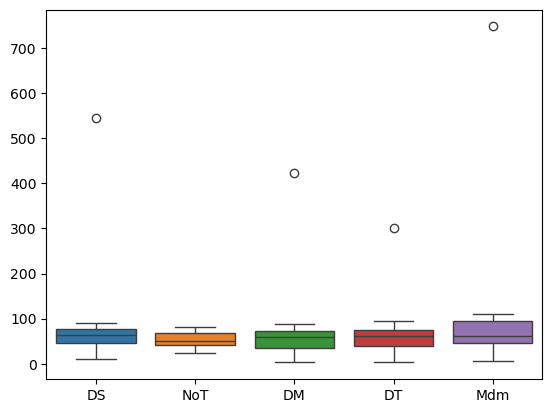

In [139]:
df1=df.drop(['Roll No','Name'] ,axis=1)
sns.boxplot(df1)
plt.show()

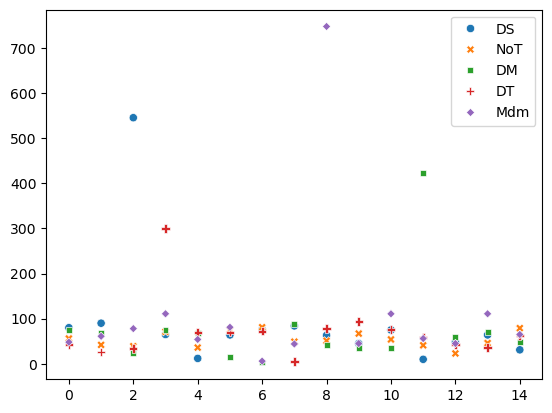

In [140]:
sns.scatterplot(df1)
plt.show()

In [141]:
data= np.array(df1['DS'])
result= iqr(data)
print(f"IQR:{result}")

IQR:31.5


In [142]:
q1= np.percentile(df1['DS'], 25)
q3= np.percentile(df1['DS'], 75)
IQR=q3-q1
print(q1,q3,IQR)

46.5 78.0 31.5


In [143]:
lower_l=q1-1.5*IQR
upper_l=q3+1.5*IQR
new_df=df[(df["DS"]<=upper_l)&(df["DS"]>=lower_l)]
new_df

,Roll No,Name,DS,NoT,DM,DT,Mdm
0,1,Rakesh,80,56.0,74,42,48.000000
1,2,Yogesh,90,42.0,69,26,61.000000
3,4,Sujal,65,71.0,75,300,110.833333
4,5,Manish,12,36.0,68,70,54.000000
5,6,Sham,64,75.0,15,70,81.000000
6,7,Virat,76,81.0,3,72,6.000000
7,8,Roshan,84,49.0,89,5,44.000000
8,9,Om,63,51.0,41,78,747.000000
9,10,Vinod,45,67.0,36,94,45.000000
10,11,Ram,75,54.0,36,76,110.833333


[3.64567475e-01 2.89139722e-01 1.90503429e-01 8.24532959e-17
 3.29754666e-01 1.73097024e-01 6.08257140e-01 3.87776015e-01
 3.69112481e+00 3.81973880e-01 8.24532959e-17 3.18150396e-01
 3.81973880e-01 8.24532959e-17 2.65931182e-01]


,DS,NoT,DM,DT,Mdm
0,80,56.0,74,42,48.000000
1,90,42.0,69,26,61.000000
2,545,39.0,24,34,78.000000
3,65,71.0,75,300,110.833333
4,12,36.0,68,70,54.000000
5,64,75.0,15,70,81.000000
6,76,81.0,3,72,6.000000
7,84,49.0,89,5,44.000000
8,63,51.0,41,78,747.000000
9,45,67.0,36,94,45.000000


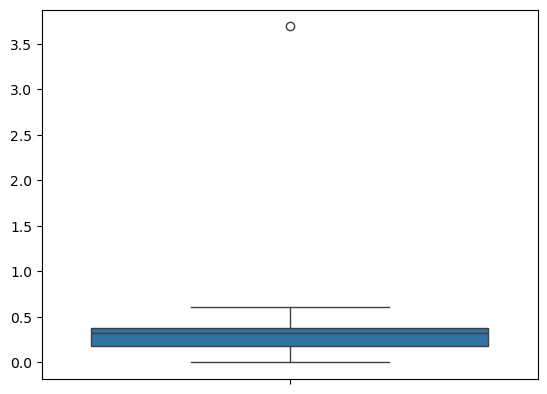

In [144]:
z=np.abs(zscore(df1["Mdm"]))
print(z)
sns.boxplot(z)
df1

In [145]:
df1


,DS,NoT,DM,DT,Mdm
0,80,56.0,74,42,48.000000
1,90,42.0,69,26,61.000000
2,545,39.0,24,34,78.000000
3,65,71.0,75,300,110.833333
4,12,36.0,68,70,54.000000
5,64,75.0,15,70,81.000000
6,76,81.0,3,72,6.000000
7,84,49.0,89,5,44.000000
8,63,51.0,41,78,747.000000
9,45,67.0,36,94,45.000000


In [153]:
df1.loc[z > 2, 'Mdm'] = df1['Mdm'].median()

In [160]:
data =np.array(df[["DT"]])  #df[['DT']] should be correctly given in syntax otherwise it will only accept the single value in the array it should be a 2d array instead of 1d array

scaler=MinMaxScaler(feature_range=(0,1))

normalized_data=scaler.fit_transform(data)
print(normalized_data)

[[0.12542373]
 [0.07118644]
 [0.09830508]
 [1.        ]
 [0.22033898]
 [0.22033898]
 [0.22711864]
 [0.        ]
 [0.24745763]
 [0.30169492]
 [0.24067797]
 [0.18305085]
 [0.12542373]
 [0.10508475]
 [0.19322034]]


In [158]:
data1 =np.array(df[["DM"]])
sscaler=StandardScaler()
scaled_data=sscaler.fit_transform(data1)
print(scaled_data)

[[-0.01459772]
 [-0.06673245]
 [-0.53594496]
 [-0.00417078]
 [-0.07715939]
 [-0.62978747]
 [-0.7549108 ]
 [ 0.14180645]
 [-0.3586869 ]
 [-0.41082163]
 [-0.41082163]
 [ 3.62440602]
 [-0.17100189]
 [-0.04587856]
 [-0.28569829]]
